# GEOM7001 — Reproduce and Save 1-Year Random Forest Predictions

**Run all cells from top to bottom in DEA Sandbox.** This standalone notebook reproduces the original 1-year optical-only and optical+SAR training workflow and saves **both** model predictions, models, metrics, and a four-panel plot (when the 5-year CSV is supplied).

### Files required in the same folder
- `model_data_2016_2025.nc` — processed monthly dataset
- `Study_site_output.json` — **original study-area polygon** used in `GEOM7001_ML_Modelling.ipynb`
- `predictions_1year_test.csv` — original 1-year predictions for verification
- `predictions_5year_test.csv` — optional; needed only for four-panel figure

The original data processing, 500 m spatial-block split, 200,000 training-sample selection and 100-tree RF settings are retained. **Original CSV is not overwritten.**

In [1]:
from pathlib import Path
import json, gc
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import joblib
from shapely.geometry import shape
from rasterio.features import geometry_mask
from affine import Affine
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

required = ["model_data_2016_2025.nc", "Study_site_output.json", "predictions_1year_test.csv"]
missing = [f for f in required if not Path(f).is_file()]
if missing:
    raise FileNotFoundError("Upload these files to the notebook folder first: " + ", ".join(missing))
print("All required inputs found.")

All required inputs found.


## 1. Load processed dataset and reproduce the original study-area mask

In [2]:
ds = xr.open_dataset("model_data_2016_2025.nc")
with open("Study_site_output.json") as f:
    geojson = json.load(f)
geom = shape(geojson["features"][0]["geometry"])
x_res = float(ds.x.values[1] - ds.x.values[0])
y_res = float(ds.y.values[1] - ds.y.values[0])
transform = Affine(x_res, 0, ds.x.values[0] - x_res/2,
                   0, y_res, ds.y.values[0] - y_res/2)
mask = geometry_mask([geom], out_shape=(ds.sizes["y"], ds.sizes["x"]),
                     transform=transform, invert=True)
study_mask = xr.DataArray(mask, coords={"y": ds.y, "x": ds.x}, dims=("y", "x"))
masked = ds.where(study_mask)
print("Masked study pixels:", int(study_mask.sum()))
print("Months:", ds.sizes["time"])

Masked study pixels: 28145
Months: 120


## 2. Rebuild 1-year and 5-year sample availability (for the original shared-block split)

In [3]:
dates = pd.DatetimeIndex(masked.time.values)
def date_pairs(months):
    return [(t, t + pd.DateOffset(months=months)) for t in dates
            if t + pd.DateOffset(months=months) in dates]

FEATURES_SAR = ["NDVI", "EVI", "NDRE", "VV", "VH"]
FEATURES_OPT = ["NDVI", "EVI", "NDRE"]

def build_samples(dataset, pairs):
    frames = []
    for t, future in pairs:
        predictors = dataset[FEATURES_SAR].sel(time=t, drop=True)
        target = dataset["FVC"].sel(time=future, drop=True)
        sample = xr.Dataset({**{k: predictors[k] for k in FEATURES_SAR}, "FVC_target": target})
        df = sample.to_dataframe().reset_index()
        df["predictor_date"] = t
        df["target_date"] = future
        frames.append(df)
    out = pd.concat(frames, ignore_index=True).dropna(subset=FEATURES_SAR+["FVC_target"])
    out["block_x"] = (out["x"] // 500).astype(int)
    out["block_y"] = (out["y"] // 500).astype(int)
    out["block_id"] = out["block_x"].astype(str) + "_" + out["block_y"].astype(str)
    return out

samples_1yr = build_samples(masked, date_pairs(12))
print("1-year samples:", len(samples_1yr))
# Only block identifiers are required from 5-year samples; use the same function as the original notebook.
samples_5yr = build_samples(masked, date_pairs(60))
print("5-year samples:", len(samples_5yr))

1-year samples: 2431453
5-year samples: 1342009


## 3. Reproduce the exact spatial split and verify against saved test records

In [4]:
common_blocks = np.intersect1d(samples_1yr["block_id"].unique(), samples_5yr["block_id"].unique())
rng = np.random.default_rng(42)
test_blocks = rng.choice(common_blocks, size=round(len(common_blocks)*0.20), replace=False)
train_blocks = np.setdiff1d(common_blocks, test_blocks)
train_1yr = samples_1yr[samples_1yr["block_id"].isin(train_blocks)].copy()
test_1yr = samples_1yr[samples_1yr["block_id"].isin(test_blocks)].copy()
saved = pd.read_csv("predictions_1year_test.csv")
print("Train:", len(train_1yr), "Test:", len(test_1yr), "Original CSV:", len(saved))
assert len(test_1yr) == len(saved) == 518615, "Original test sample count not reproduced; STOP."
assert set(test_1yr.block_id) == set(saved.block_id), "Original test blocks differ; STOP."
assert set(train_1yr.block_id).isdisjoint(set(test_1yr.block_id))
# Verify exact membership via unique spatial-temporal keys, not row ordering.
keys = ["x", "y", "predictor_date", "target_date"]
for d in (saved, test_1yr):
    d["predictor_date"] = pd.to_datetime(d["predictor_date"])
    d["target_date"] = pd.to_datetime(d["target_date"])
assert not saved.duplicated(keys).any() and not test_1yr.duplicated(keys).any()
check = saved[keys].merge(test_1yr[keys], on=keys, how="outer", indicator=True)
assert (check["_merge"] == "both").all(), "Original test rows do not match; STOP."
del samples_5yr, check
gc.collect()
print("PASS: Original 1-year spatial test set recovered exactly.")

Train: 1912827 Test: 518615 Original CSV: 518615
PASS: Original 1-year spatial test set recovered exactly.


## 4. Train both 1-year models and calculate metrics

In [5]:
train_sample = train_1yr.sample(n=min(200_000, len(train_1yr)), random_state=42)
y_test = test_1yr["FVC_target"].to_numpy()

def fit_and_predict(features):
    rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(train_sample[features], train_sample["FVC_target"])
    pred = rf.predict(test_1yr[features])
    metrics = {"MAE": mean_absolute_error(y_test, pred),
               "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
               "R2": r2_score(y_test, pred)}
    return rf, pred, metrics

print("Training Optical-only...")
rf_opt, pred_opt, metrics_opt = fit_and_predict(FEATURES_OPT)
print("Training Optical + SAR...")
rf_sar, pred_sar, metrics_sar = fit_and_predict(FEATURES_SAR)
metrics = pd.DataFrame([metrics_opt, metrics_sar], index=["1-Year Optical-only", "1-Year Optical + SAR"])
print(metrics.round(3).to_string())

Training Optical-only...
Training Optical + SAR...
                        MAE    RMSE     R2
1-Year Optical-only   7.995  11.173  0.316
1-Year Optical + SAR  7.757  10.891  0.350


## 5. Verify results and save models, complete predictions and metrics

Original reference metrics: Optical-only MAE 7.995, RMSE 11.173, R² 0.316; Optical+SAR MAE 7.757, RMSE 10.891, R² 0.350. If the reconstructed metrics differ, inspect the output before using it in the report. Outputs use **new filenames** to protect originals.

In [6]:
# Compare new SAR predictions with the original saved CSV, matched by coordinates and dates.
new = test_1yr[keys + ["block_id", "FVC_target"]].copy()
new["FVC_pred_optical"] = pred_opt
new["FVC_pred_optical_sar"] = pred_sar
comparison = saved[keys + ["FVC_pred_optical_sar"]].merge(
    new[keys + ["FVC_pred_optical_sar"]], on=keys, how="inner", validate="one_to_one", suffixes=("_old", "_new"))
assert len(comparison) == len(saved)
max_diff = np.max(np.abs(comparison["FVC_pred_optical_sar_old"] - comparison["FVC_pred_optical_sar_new"]))
print("Maximum SAR prediction difference vs original CSV:", max_diff)
print("Reference metrics are rounded to 3 decimal places.")
if max_diff > 1e-5:
    print("WARNING: Retrained SAR predictions differ from saved results. Check metrics before using the new CSV.")

# Preserve the original CSV row order and its saved SAR values; add optical predictions by exact keys.
opt_only = new[keys + ["FVC_pred_optical"]]
completed = saved.merge(opt_only, on=keys, how="left", validate="one_to_one")
assert completed["FVC_pred_optical"].notna().all()
completed.to_csv("predictions_1year_test_COMPLETE.csv", index=False)
metrics.to_csv("model_performance_1year_REPRODUCED.csv")
joblib.dump(rf_opt, "rf_1year_optical_REPRODUCED.joblib", compress=3)
joblib.dump(rf_sar, "rf_1year_optical_sar_REPRODUCED.joblib", compress=3)
print("Saved predictions_1year_test_COMPLETE.csv and both models.")

Maximum SAR prediction difference vs original CSV: 0.0
Reference metrics are rounded to 3 decimal places.
Saved predictions_1year_test_COMPLETE.csv and both models.


## 6. Create the complete four-panel observed-versus-predicted plot

The two 1-year panels use the completed CSV; the two 5-year panels use the previously saved test predictions. Metrics are computed from the plotted records, not hard-coded.

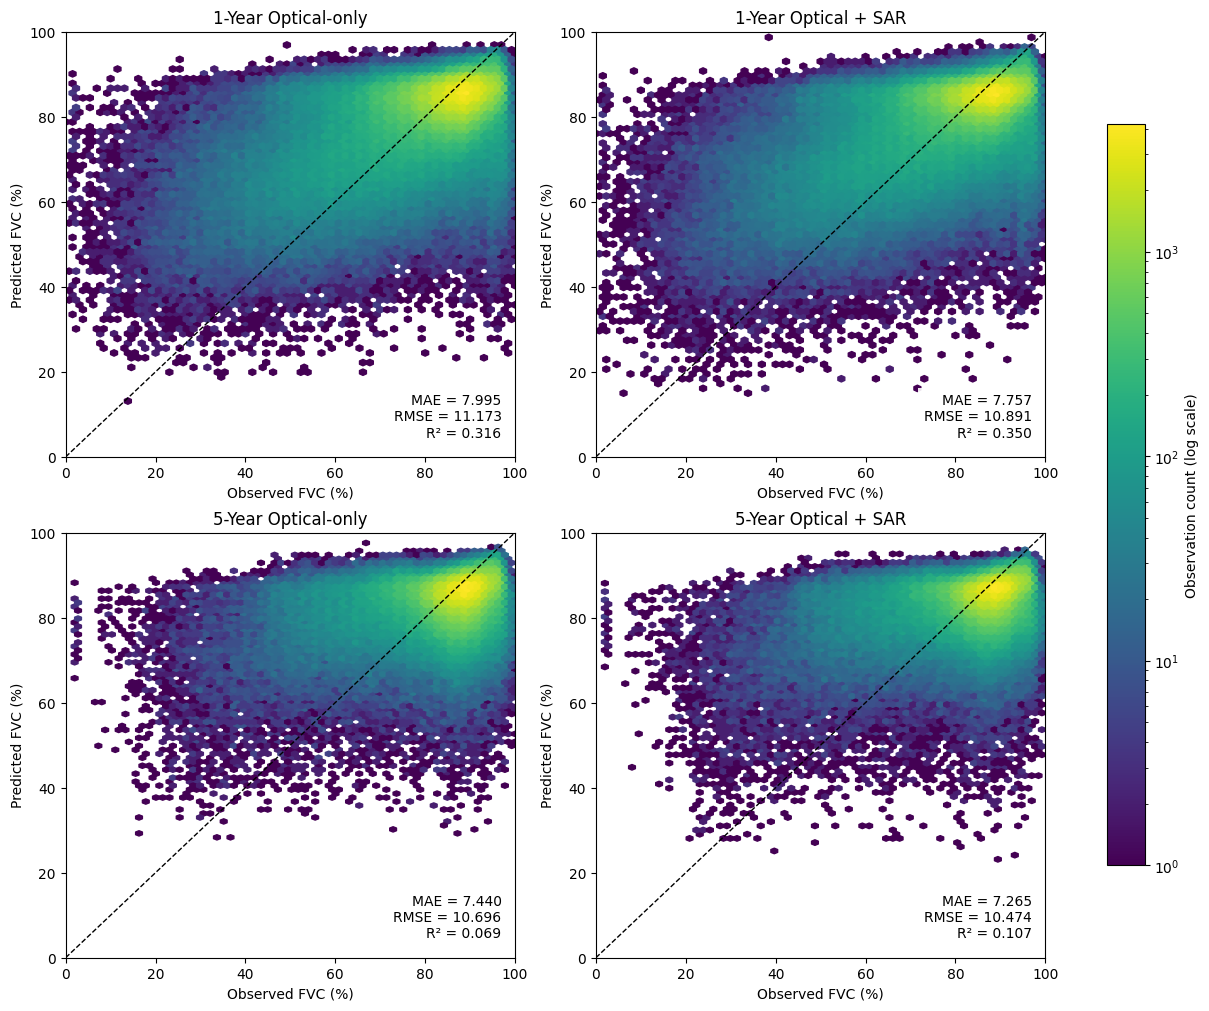

Saved Observed_vs_Predicted_FVC_4_Models.png


In [7]:
from matplotlib.colors import LogNorm

if not Path("predictions_5year_test.csv").is_file():
    print("Upload predictions_5year_test.csv to generate the four-panel plot.")
else:
    five = pd.read_csv("predictions_5year_test.csv")
    panels = [
        (completed, "FVC_pred_optical", "1-Year Optical-only"),
        (completed, "FVC_pred_optical_sar", "1-Year Optical + SAR"),
        (five, "FVC_pred_optical", "5-Year Optical-only"),
        (five, "FVC_pred_optical_sar", "5-Year Optical + SAR"),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
    for ax, (frame, col, title) in zip(axes.flat, panels):
        actual = frame["FVC_target"].to_numpy()
        pred = frame[col].to_numpy()
        hb = ax.hexbin(actual, pred, gridsize=65, mincnt=1, norm=LogNorm(), cmap="viridis")
        ax.plot([0, 100], [0, 100], "--", color="black", lw=1)
        ax.set(xlim=(0, 100), ylim=(0, 100), title=title,
               xlabel="Observed FVC (%)", ylabel="Predicted FVC (%)")
        ax.text(.97, .04, f"MAE = {mean_absolute_error(actual,pred):.3f}\n"
                f"RMSE = {np.sqrt(mean_squared_error(actual,pred)):.3f}\n"
                f"R² = {r2_score(actual,pred):.3f}",
                transform=ax.transAxes, ha="right", va="bottom",
                bbox=dict(facecolor="white", alpha=.9, edgecolor="none"))
    fig.colorbar(hb, ax=axes.ravel().tolist(), label="Observation count (log scale)", shrink=.8)
    fig.savefig("Observed_vs_Predicted_FVC_4_Models.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved Observed_vs_Predicted_FVC_4_Models.png")

## Output files

- `predictions_1year_test_COMPLETE.csv` — original 1-year SAR predictions **plus recovered optical-only predictions**
- `rf_1year_optical_REPRODUCED.joblib`
- `rf_1year_optical_sar_REPRODUCED.joblib`
- `model_performance_1year_REPRODUCED.csv`
- `Observed_vs_Predicted_FVC_4_Models.png` (if 5-year CSV supplied)

**Interpretation:** FVC is Landsat-derived fractional cover, not field-measured ground truth. Spatial test blocks assess spatial generalisation; this is not a temporally independent forecast evaluation.